In [2]:
pip install pandas numpy scikit-learn xgboost matplotlib seaborn ipywidgets opendatasets

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, precision_recall_curve
from xgboost import XGBClassifier

# For interactive widgets in Jupyter
import ipywidgets as widgets
from IPython.display import display, clear_output

In [4]:
# Load the dataset (using raw string for Windows path)
df = pd.read_csv(r"C:\Users\hp\ai4i2020.csv")

# Clean column names: Remove units inside brackets and replace spaces with underscores
# e.g., "Air temperature [K]" becomes "Air_temperature"
df = df.rename(columns=lambda x: x.split(' [')[0].strip().replace(' ', '_'))

print("Cleaned Columns:")
print(df.columns.tolist())

# Check class distribution (showing the imbalance)
print("\nClass Distribution:")
print(df['Machine_failure'].value_counts(normalize=True))

Cleaned Columns:
['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Class Distribution:
Machine_failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64


In [5]:
# Select the clean numerical feature names
numeric_features = [
    'Air_temperature', 
    'Process_temperature', 
    'Rotational_speed', 
    'Torque', 
    'Tool_wear'
]

X = df[numeric_features]
y = df['Machine_failure']

# Stratified train-test split to preserve failure ratios
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8000, 5)
Testing set shape: (2000, 5)


In [6]:
neg_count = sum(y_train == 0)
pos_count = sum(y_train == 1)
scale_pos_weight_val = neg_count / pos_count

model = XGBClassifier(
    scale_pos_weight=scale_pos_weight_val, 
    random_state=42,
    eval_metric='logloss'
)

model.fit(X_train, y_train)
print("Model training complete!")

Model training complete!


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.69      0.74      0.71        68

    accuracy                           0.98      2000
   macro avg       0.84      0.86      0.85      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC Score: 0.9720


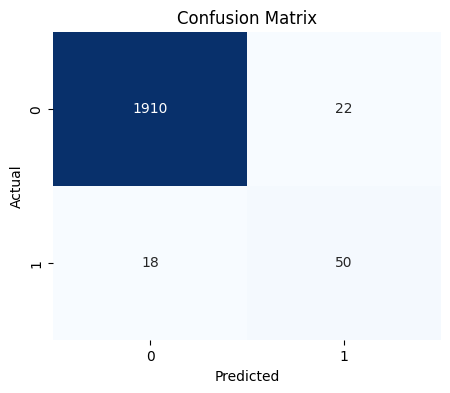

In [7]:
preds = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, preds))

roc_auc = roc_auc_score(y_test, probs)
print(f"ROC-AUC Score: {roc_auc:.4f}")

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [8]:
air_temp_widget = widgets.FloatSlider(value=298.0, min=295.0, max=305.0, step=0.5, description='Air Temp:')
proc_temp_widget = widgets.FloatSlider(value=308.0, min=305.0, max=315.0, step=0.5, description='Proc Temp:')
rot_speed_widget = widgets.IntSlider(value=1500, min=1200, max=2800, step=10, description='Speed [rpm]:')
torque_widget = widgets.FloatSlider(value=40.0, min=3.0, max=80.0, step=0.5, description='Torque:')
tool_wear_widget = widgets.IntSlider(value=100, min=0, max=250, step=5, description='Tool Wear:')

out = widgets.Output()

def predict_health(air_temp, proc_temp, rot_speed, torque, tool_wear):
    with out:
        clear_output(wait=True)
        input_df = pd.DataFrame([[air_temp, proc_temp, rot_speed, torque, tool_wear]], 
                                columns=numeric_features)
        pred = model.predict(input_df)[0]
        prob = model.predict_proba(input_df)[0][1]
        
        print("Machine Health Analysis")
        if pred == 1:
            print(f"HIGH RISK OF FAILURE! (Failure Probability: {prob:.2%})")
            print("Recommendation: Schedule immediate maintenance check.")
        else:
            print(f"Machine is Healthy. (Failure Probability: {prob:.2%})")
            print("Status: Operating within safe parameters.")

# Bind controls to function
interactive_plot = widgets.interactive(
    predict_health, 
    air_temp=air_temp_widget, 
    proc_temp=proc_temp_widget, 
    rot_speed=rot_speed_widget, 
    torque=torque_widget, 
    tool_wear=tool_wear_widget
)

display(interactive_plot, out)

interactive(children=(FloatSlider(value=298.0, description='Air Temp:', max=305.0, min=295.0, step=0.5), Float…

Output()